## Degree-3 Polynomial Approximation

**Name**: Jiaen Qi

**Date**: 09/05/2026


## Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Least-Squre Approximating Polynomial

## Explain

We want to approximate

$$
f(x)=e^x\sin(x)
$$

on $[-1,1]$ using a polynomial of degree at most 3:

$$
P_3^{LS}(x)=a_0+a_1x+a_2x^2+a_3x^3.
$$

The total squared error is

$$
E(a_0,a_1,a_2,a_3)
=
\int_{-1}^{1}
\left(f(x)-\sum_{j=0}^{3}a_jx^j\right)^2\,dx.
$$

To minimize this error, we take the partial derivative with respect
to each coefficient $a_i$ and set it equal to zero:

$$
\frac{\partial E}{\partial a_i}
=
-2\int_{-1}^{1}
\left(f(x)-\sum_{j=0}^{3}a_jx^j\right)x^i\,dx
=0,
\qquad i=0,1,2,3.
$$

Moving the polynomial terms to the other side gives the normal equations:

$$
\sum_{j=0}^{3}a_j\int_{-1}^{1}x^{i+j}\,dx
=
\int_{-1}^{1}f(x)x^i\,dx,
\qquad i=0,1,2,3.
$$

The integrals on the left are easy to calculate:

$$
\int_{-1}^{1}x^k\,dx
=
\begin{cases}
0, & k \text{ is odd},\\
\frac{2}{k+1}, & k \text{ is even}.
\end{cases}
$$

Therefore, the system is

$$
\begin{bmatrix}
2 & 0 & 2/3 & 0\\
0 & 2/3 & 0 & 2/5\\
2/3 & 0 & 2/5 & 0\\
0 & 2/5 & 0 & 2/7
\end{bmatrix}
\begin{bmatrix}
a_0\\a_1\\a_2\\a_3
\end{bmatrix}
=
\begin{bmatrix}
\int_{-1}^{1}e^x\sin(x)\,dx\\
\int_{-1}^{1}xe^x\sin(x)\,dx\\
\int_{-1}^{1}x^2e^x\sin(x)\,dx\\
\int_{-1}^{1}x^3e^x\sin(x)\,dx
\end{bmatrix}.
$$

This system gives the unique minimum because its matrix is positive
definite. For any nonzero coefficient vector $c$,

$$
c^TAc
=
\int_{-1}^{1}
(c_0+c_1x+c_2x^2+c_3x^3)^2\,dx
>0.
$$

## Implement

Next, we will solve  the normal equations

$$
A\mathbf{a}=\mathbf{b},
$$

where

$$
A_{ij}=\int_{-1}^{1}x^{i+j}\,dx,
\qquad
b_i=\int_{-1}^{1}e^x\sin(x)x^i\,dx.
$$

And we will calculate the entries of $A$ exactly and approximate the integrals
in $\mathbf{b}$ using the composite Simpson's rule:

$$
\int_{-1}^{1}g(x)\,dx
\approx
\frac{h}{3}
\left[
g(x_0)
+4\sum_{\substack{k=1\\k\text{ odd}}}^{n-1}g(x_k)
+2\sum_{\substack{k=2\\k\text{ even}}}^{n-2}g(x_k)
+g(x_n)
\right],
$$

where $n$ is even and $h=2/n$.
Then we use `numpy.linalg.solve` to find the four coefficients.

In [ ]:
def f(x):
  return np.exp(x) * np.sin(x)

# build the normal equation matrix using exact integrals

A = np.zeros((4,4))

for i in range(4):
  for j in range(4):
    power = i + j

    if power % 2 == 0:
      A[i,j] = 2 / (power + 1)

# Then we use Simpson's Rule, which needs an even number of subintervals
n = 1000
x = np.linspace(-1, 1, n + 1)
h = 2 / n

b = np.zeros(4)

for i in range(4):
  y = f(x) * x**i
  b[i] = (h/3) * (
      y[0] + y[-1]
      + 4 * np.sum(y[1:-1:2])
      + 2 * np.sum(y[2:-1:2])
  )

# Then we solve for a0, a1, a2, and a3

a = np.linalg.solve(A,b)

np.set_printoptions(precision=10, suppress=True)

print("Normal-equation system: A @ a = b")
print("A =")
print(A)
print("b =")
print(b)

print("Coefficients:")
for i in range(4):
    print(f"a{i} = {a[i]:.10f}")

print("Final polynomial:")
print(
    f"P3_LS(x) = {a[0]:.10f}"
    f" {a[1]:+.10f}x"
    f" {a[2]:+.10f}x^2"
    f" {a[3]:+.10f}x^3"
)

# Define the polynomial for plotting and error calculations later.
def P(x):
    return a[0] + a[1]*x + a[2]*x**2 + a[3]*x**3

Normal-equation system: A @ a = b
A =
[[2.           0.           0.6666666667 0.          ]
 [0.           0.6666666667 0.           0.4         ]
 [0.6666666667 0.           0.4          0.          ]
 [0.           0.4          0.           0.2857142857]]
b =
[0.6634936666 0.7901315954 0.3975322207 0.4875489766]
Coefficients:
a0 = 0.0010574612
a1 = 1.0084033897
a2 = 0.9920681165
a3 = 0.2946566724
Final polynomial:
P3_LS(x) = 0.0010574612 +1.0084033897x +0.9920681165x^2 +0.2946566724x^3


From above, the least-squares polynomial is approximately

$$
P_3{(x)}
=
0.0010574612
+1.0084033897x
+0.9920681165x^2
+0.2946566724x^3.
$$

These coefficients minimize the integrated squared error on $[-1,1]$,
up to numerical integration and rounding errors. The polynomial does
not have to pass through specific points of the original function.

## Experiment and Example

Next, we will plot $f(x)=e^x\sin(x)$ and $P_3^{LS}(x)$ on $[-2,2]$,
with the approximation interval $[-1,1]$ shaded.

On a fine grid of $N=10001$ points in $[-1,1]$, we calculate
the maximum absolute error and root-mean-square error:

$$
E_{\max}=\max_{0\leq k<N}|f(x_k)-P_3^{LS}(x_k)|
$$

$$
\mathrm{RMSE}
=
\sqrt{\frac{1}{N}\sum_{k=0}^{N-1}
\left(f(x_k)-P_3^{LS}(x_k)\right)^2}.
$$

These values measure the error at the sampled grid points.

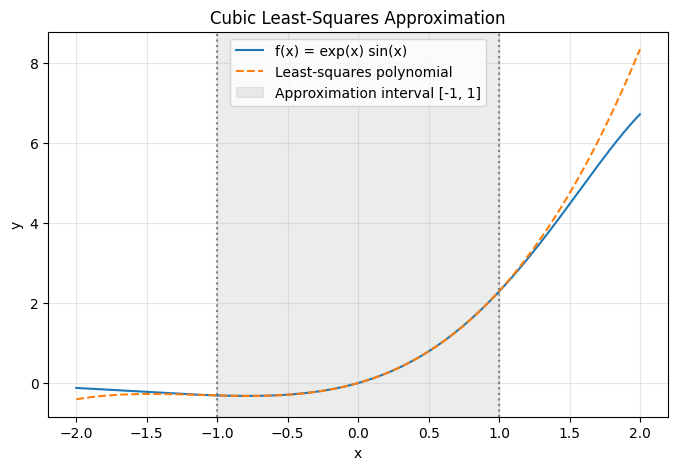

Maximum absolute error: 0.0088303526
Root-mean-square error: 0.0018053763


In [ ]:
x_plot = np.linspace(-2, 2, 1000)

plt.figure(figsize=(8, 5))
plt.plot(x_plot, f(x_plot), label="f(x) = exp(x) sin(x)")
plt.plot(x_plot, P(x_plot), "--", label="Least-squares polynomial")

# Mark the interval used to calculate the approximation.
plt.axvspan(-1, 1, color="gray", alpha=0.15,
            label="Approximation interval [-1, 1]")
plt.axvline(-1, color="gray", linestyle=":")
plt.axvline(1, color="gray", linestyle=":")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Least-Squares Approximation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Measure the error only within [-1, 1].
x_grid = np.linspace(-1, 1, 10001)
error = f(x_grid) - P(x_grid)

max_error = np.max(np.abs(error))
rmse = np.sqrt(np.mean(error**2))

print(f"Maximum absolute error: {max_error:.10f}")
print(f"Root-mean-square error: {rmse:.10f}")

As we can see from the graph, the polynomial follows the original function `closely` on $[-1,1]$.

Outside this interval, the curves are more and more separated.

This happens because we minimized the squared error `only on $[-1,1]$`,
so the polynomial is not guaranteed to approximate the function well
outside that interval.

## Conclusion

The degree-3 least-squares polynomial approximates $e^x\sin(x)$ closely on $[-1,1]$.
It minimizes the integrated squared error over this interval.

However, it does not necessarily minimize the maximum absolute error.
The approximation becomes less accurate outside $[-1,1]$.

## Lagrange Polynomial with Equally Spcaced Nodes

## Explain

We use four equally spaced nodes on $[-1,1]$:

$$
x_0=-1,\qquad x_1=-\frac13,\qquad
x_2=\frac13,\qquad x_3=1.
$$

The Lagrange interpolating polynomial is

$$
P_3(x)=\sum_{i=0}^{3}f(x_i)L_i(x),
$$

where each basis polynomial is defined by

$$
L_i(x)=
\prod_{\substack{j=0\\j\ne i}}^{3}
\frac{x-x_j}{x_i-x_j}.
$$

Each $L_i(x)$ contains three linear factors, so its degree is 3.
The denominators are nonzero because the nodes are distinct.

At its own node, every factor equals 1. At any other node,
one factor equals 0. Therefore,

$$
L_i(x_k)=
\begin{cases}
1, & k=i,\\
0, & k\ne i.
\end{cases}
$$

This means that at $x_k$, only the term $f(x_k)L_k(x_k)$ remains:

$$
P_3(x_k)=f(x_k).
$$

Thus, $P_3$ has degree at most 3 and passes through all four
specified points. Unlike least squares, this method matches the
function exactly at the nodes instead of minimizing the integrated
squared error.

## Implement

We implement the Lagrange formula using loops to calculate each
basis polynomial and add its contribution.

To display the result in the form

$$
P_3(x)=c_0+c_1x+c_2x^2+c_3x^3,
$$

we also expand the basis polynomials by multiplying their linear
factors manually.

In [ ]:
def lagrange(x, nodes, values):
    x = np.asarray(x, dtype=float)
    result = np.zeros_like(x)

    for i in range(len(nodes)):
        basis = np.ones_like(x)

        for j in range(len(nodes)):
            if j != i:
                basis *= (x - nodes[j]) / (nodes[i] - nodes[j])

        result += values[i] * basis

    return result


# Four equally spaced nodes and their function values.
nodes = np.linspace(-1, 1, 4)
values = f(nodes)

print("Node          Function value")
for xi, yi in zip(nodes, values):
    print(f"{xi: .10f}   {yi: .10f}")


# Expand the Lagrange formula.
# Coefficients are stored in increasing powers of x.
c = np.zeros(len(nodes))

for i in range(len(nodes)):
    basis_coeff = np.array([1.0])

    for j in range(len(nodes)):
        if j != i:
            # Multiply the current polynomial by (x - nodes[j]).
            new_coeff = np.zeros(len(basis_coeff) + 1)
            new_coeff[:-1] -= nodes[j] * basis_coeff
            new_coeff[1:] += basis_coeff

            basis_coeff = new_coeff / (nodes[i] - nodes[j])

    c += values[i] * basis_coeff

print("\nExpanded polynomial:")
print(
    f"P3_L(x) = {c[0]:.10f}"
    f" {c[1]:+.10f}x"
    f" {c[2]:+.10f}x^2"
    f" {c[3]:+.10f}x^3"
)


# Use the general function for later plots and error calculations.
def P_L(x):
    return lagrange(x, nodes, values)


# Check that the polynomial matches the function at the nodes.
node_error = np.max(np.abs(P_L(nodes) - values))
print(f"\nMaximum error at the nodes: {node_error:.3e}")

Node          Function value
-1.0000000000   -0.3095598757
-0.3333333333   -0.2344452449
 0.3333333333    0.4566369843
 1.0000000000    2.2873552872

Expanded polynomial:
P3_L(x) = 0.0013706402 +1.0038940641x +0.9875270656x^2 +0.2945635174x^3

Maximum error at the nodes: 0.000e+00


The polynomial matches the function at all four nodes, up to
floating-point rounding. However, matching these points does not
guarantee a small error everywhere between them.

## Experiment and Example

We plot the Lagrange polynomial and the original function on $[-2,2]$
and mark the four interpolation nodes.

Using the same 10001-point grid on $[-1,1]$, we calculate

$$
E_{\max}=\max_k |f(x_k)-P_3^L(x_k)|
$$

and

$$
\mathrm{RMSE}
=
\sqrt{\frac{1}{N}\sum_{k=0}^{N-1}
\left(f(x_k)-P_3^L(x_k)\right)^2}.
$$

We compare these errors with the least-squares polynomial.

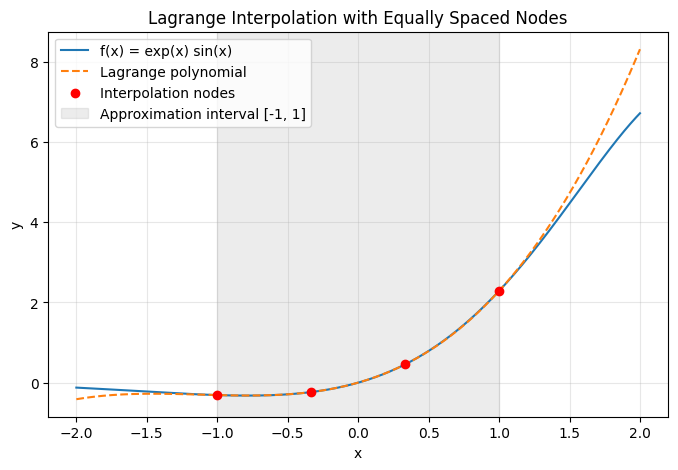

       Method  Maximum absolute error         RMSE
Least squares            0.0088303526 0.0018053763
     Lagrange            0.0091961832 0.0036709572


In [ ]:
# Plot the function and Lagrange polynomial.
x_plot = np.linspace(-2, 2, 1000)

plt.figure(figsize=(8, 5))
plt.plot(x_plot, f(x_plot), label="f(x) = exp(x) sin(x)")
plt.plot(x_plot, P_L(x_plot), "--", label="Lagrange polynomial")
plt.scatter(nodes, values, color="red", zorder=5,
            label="Interpolation nodes")
plt.axvspan(-1, 1, color="gray", alpha=0.15,
            label="Approximation interval [-1, 1]")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Lagrange Interpolation with Equally Spaced Nodes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Use the same fine grid as in Part 1.C.
x_grid = np.linspace(-1, 1, 10001)

error_ls = f(x_grid) - P(x_grid)
error_l = f(x_grid) - P_L(x_grid)

# Compare both methods in a table.
comparison = pd.DataFrame({
    "Method": ["Least squares", "Lagrange"],
    "Maximum absolute error": [
        np.max(np.abs(error_ls)),
        np.max(np.abs(error_l))
    ],
    "RMSE": [
        np.sqrt(np.mean(error_ls**2)),
        np.sqrt(np.mean(error_l**2))
    ]
})

print(comparison.to_string(index=False, float_format=lambda v: f"{v:.10f}"))

As we can see from the graph, The graph shows that the Lagrange polynomial follows the function closely
on $[-1,1]$ and passes through all four nodes. Outside this interval,
the curves separate, especially toward $x=2$.

The least-squares polynomial has a slightly smaller maximum absolute
error: about $0.008830$, compared with $0.009196$ for Lagrange.
Its RMSE is also smaller: about $0.001805$, compared with $0.003671$.

Thus, least squares performs better by both error measures in this
example, even though Lagrange matches the function exactly at the nodes.



## Conclusion

By using four equally spaced nodes, we can make the polynomial match the function exactly at those points.

However, errors still occur between the nodes.
In this example, Lagrange has a slightly larger maximum error and about twice the RMSE of least squares.
The approximation also becomes less accurate outside $[-1,1]$.

## Lagrange Polynomial with Chebyshev Nodes

## Explain

The fourth Chebyshev polynomial satisfies

$$
T_4(x)=8x^4-8x^2+1,
\qquad
T_4(\cos\theta)=\cos(4\theta).
$$

To find its zeros, we set $\cos(4\theta)=0$. This gives

$$
\theta_k=\frac{(2k-1)\pi}{8},
\qquad k=1,2,3,4.
$$

Therefore, the four Chebyshev nodes are

$$
x_k=\cos\left(\frac{(2k-1)\pi}{8}\right),
\qquad k=1,2,3,4.
$$

Their approximate values, listed in increasing order, are

$$
-0.923880,\quad -0.382683,\quad 0.382683,\quad 0.923880.
$$

The angles are equally spaced, but their cosine values are not.
Since cosine changes more slowly near angles $0$ and $\pi$,
the nodes are more concentrated near the endpoints of $[-1,1]$.

For cubic interpolation, the error has the form

$$
f(x)-P_3^C(x)
=
\frac{f^{(4)}(\xi_x)}{4!}
\prod_{k=1}^{4}(x-x_k),
$$

where $\xi_x$ is some point in $[-1,1]$.

Chebyshev nodes minimize the maximum absolute value of the product
term on $[-1,1]$. This can reduce large interpolation errors,
especially near the endpoints, although it does not guarantee
the smallest actual error for every function.

## Implement

We calculate the four Chebyshev nodes and evaluate $f$ at each node.
Then we use our Lagrange function from Part 2.B to construct

$$
P_3^C(x)=\sum_{i=0}^{3}f(t_i)L_i(x),
$$

where $t_0,t_1,t_2,t_3$ are the Chebyshev nodes in increasing order.
We expand the basis polynomials to display the final coefficients.

In [ ]:
k = np.arange(1, 5)
cheb_nodes = np.sort(np.cos((2*k - 1) * np.pi / 8))
cheb_values = f(cheb_nodes)

print("Node          Function value")
for xi, yi in zip(cheb_nodes, cheb_values):
    print(f"{xi: .10f}   {yi: .10f}")


# Reuse the general Lagrange function from Part 2.B.
def P_C(x):
    return lagrange(x, cheb_nodes, cheb_values)


# Expand the basis polynomials using the same method as before.
cheb_coeff = np.zeros(4)

for i in range(4):
    basis_coeff = np.array([1.0])

    for j in range(4):
        if j != i:
            # Multiply by (x - cheb_nodes[j]), then divide
            # by the corresponding denominator.
            new_coeff = np.zeros(len(basis_coeff) + 1)
            new_coeff[:-1] -= cheb_nodes[j] * basis_coeff
            new_coeff[1:] += basis_coeff

            basis_coeff = new_coeff / (cheb_nodes[i] - cheb_nodes[j])

    cheb_coeff += cheb_values[i] * basis_coeff

print("Expanded polynomial:")
print(
    f"P3_C(x) = {cheb_coeff[0]:.10f}"
    f" {cheb_coeff[1]:+.10f}x"
    f" {cheb_coeff[2]:+.10f}x^2"
    f" {cheb_coeff[3]:+.10f}x^3"
)

# Check that interpolation matches the function at the nodes.
cheb_node_error = np.max(np.abs(P_C(cheb_nodes) - cheb_values))
print(f"Maximum error at the nodes: {cheb_node_error:.3e}")

Node          Function value
-0.9238795325   -0.3167653569
-0.3826834324   -0.2546771416
 0.3826834324    0.5475005664
 0.9238795325    2.0100610338
Expanded polynomial:
P3_C(x) = 0.0013880623 +1.0043601825x +0.9902834263x^2 +0.2986446878x^3
Maximum error at the nodes: 0.000e+00


The polynomial matches the function at the four Chebyshev nodes,
up to floating-point rounding. These nodes lie inside $[-1,1]$
and do not include the endpoints. We will compare its errors with
the other two methods in the next part.

## Experiment and Example

We plot the original function and all three approximating polynomials
on $[-2,2]$.

Using the same 10001-point grid on $[-1,1]$, we compare the maximum
absolute error and RMSE:

$$
E_{\max}=\max_k|f(x_k)-P(x_k)|
$$

$$
\mathrm{RMSE}
=
\sqrt{\frac{1}{N}\sum_{k=0}^{N-1}
\left(f(x_k)-P(x_k)\right)^2}.
$$

Here, $P$ represents each of the three approximating polynomials.
Smaller values indicate greater accuracy under that error measure.

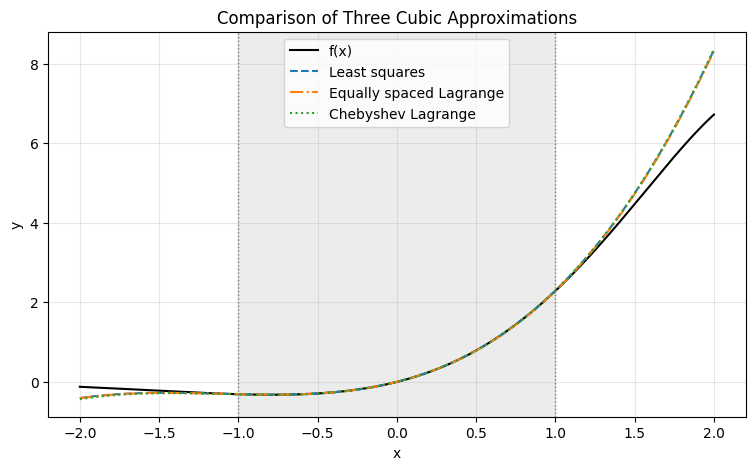

                 Method  Maximum absolute error         RMSE
          Least squares            0.0088303526 0.0018053763
Equally spaced Lagrange            0.0091961832 0.0036709572
     Chebyshev Lagrange            0.0073210717 0.0022096584

Smallest maximum error: Chebyshev Lagrange
Smallest RMSE: Least squares


In [ ]:
x_plot = np.linspace(-2, 2, 1000)

plt.figure(figsize=(9, 5))
plt.plot(x_plot, f(x_plot), color="black", label="f(x)")
plt.plot(x_plot, P(x_plot), "--", label="Least squares")
plt.plot(x_plot, P_L(x_plot), "-.", label="Equally spaced Lagrange")
plt.plot(x_plot, P_C(x_plot), ":", label="Chebyshev Lagrange")

# Mark the approximation interval.
plt.axvspan(-1, 1, color="gray", alpha=0.15)
plt.axvline(-1, color="gray", linestyle=":", linewidth=1)
plt.axvline(1, color="gray", linestyle=":", linewidth=1)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Comparison of Three Cubic Approximations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Calculate all errors on the same grid within [-1, 1].
x_grid = np.linspace(-1, 1, 10001)

methods = [
    ("Least squares", P),
    ("Equally spaced Lagrange", P_L),
    ("Chebyshev Lagrange", P_C)
]

rows = []

for name, polynomial in methods:
    error = f(x_grid) - polynomial(x_grid)
    rows.append({
        "Method": name,
        "Maximum absolute error": np.max(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error**2))
    })

comparison_all = pd.DataFrame(rows)

print(comparison_all.to_string(
    index=False,
    float_format=lambda v: f"{v:.10f}"
))

# Identify the best method for each error measure.
best_max = comparison_all["Maximum absolute error"].idxmin()
best_rmse = comparison_all["RMSE"].idxmin()

print("\nSmallest maximum error:",
      comparison_all.loc[best_max, "Method"])
print("Smallest RMSE:",
      comparison_all.loc[best_rmse, "Method"])

Chebyshev interpolation has the smallest maximum absolute error,
about $0.007321$, compared with $0.008830$ for least squares and
$0.009196$ for equally spaced interpolation.

Least squares has the smallest RMSE, about $0.001805$, followed by
Chebyshev interpolation at $0.002210$ and equally spaced interpolation
at $0.003671$. Thus, the most accurate method depends on the error
measure: Chebyshev is best for maximum error in this experiment,
while least squares is best for RMSE.

All three polynomials approximate the function closely on $[-1,1]$.
Outside this interval, they deviate more from the function, especially
toward $x=2$. Their accuracy on $[-1,1]$ does not guarantee accuracy
outside it.

## Conclusion

Least squares gives the `smallest` RMSE but requires integrals and solving a linear system.
Equally spaced Lagrange interpolation uses simple nodes but has the `largest errors` in this experiment.

Chebyshev interpolation gives the `smallest maximum error` and improves on equally spaced nodes.

Both interpolation methods use the same Lagrange code, with only the nodes changed.
All three methods work well on $[-1,1]$, but become `less accurate` outside this interval.